# Drawing diagrams

A diagram as a graph: inline in Jupyter, as text, as a file, as Graphviz
DOT or Mermaid. All use one layout: columns by signal flow, feedback lines
dashed below.

In [1]:
import tempfile
from pathlib import Path

import scipy.signal as sig

import sigline as sl

fs = 48_000.0

## A receiver with an AGC loop

Two tones and noise, low-pass, then an automatic gain control: the output
level is compared with a reference and integrated, one chunk late through a
`Delay`.

In [2]:
add, lp = sl.Sum(name="add"), sl.FIR(sig.firwin(101, 3e3, fs=fs), name="lp")
sl.Sine(1e3, name="tone") >> add["x0"]
sl.Noise(0.05, seed=1, name="noise") >> add["x1"]
add >> lp

vga, level, err = (
    sl.Product(name="vga"),
    sl.Func(lambda x: x**2, name="level"),
    sl.Sum("-+", name="err"),
)
integ = sl.IIR(b=[1e-3], a=[1.0, -1.0], name="integ")
lp >> vga["x0"]
vga >> level >> err["x0"]
sl.Const(0.5, name="ref") >> err["x1"]
err >> integ >> sl.Delay(1024, name="z", init=1.0) >> vga["x1"]
vga >> sl.Scope("out")

d = sl.Diagram(vga, fs=fs)
p = d.probe("lp")

## Inline

A cell ending with the diagram shows it.

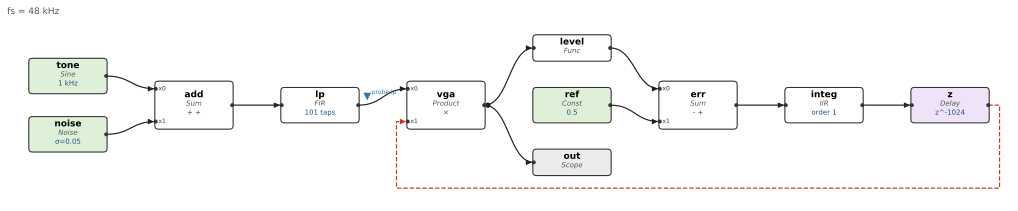

In [3]:
d

## Text

In [4]:
print(d)

Diagram  fs = 48 kHz  |  11 blocks, 11 lines, 1 feedback

signal flow:
  tone ──▶ add[x0]
  noise ──▶ add[x1]
  add ──▶ lp ──▶ vga[x0]
  vga ──▶ level ──▶ err[x0]
  vga ──▶ out
  ref ──▶ err[x1]
  err ──▶ integ ──▶ z
feedback:
  z ══⟲══▶ vga[x1]
probes:
  probe:lp  <-  lp[y]

blocks:
  [0] tone   Sine     1 kHz
  [0] noise  Noise    σ=0.05
  [1] add    Sum      + +
  [2] lp     FIR      101 taps
  [3] vga    Product  ×
  [4] level  Func
  [4] ref    Const    0.5
  [4] out    Scope
  [5] err    Sum      - +
  [6] integ  IIR      order 1
  [7] z      Delay    z^-1024


## Files

`d.draw(save=...)` writes any matplotlib format: PDF for documents, SVG for
the web, PNG for slides.

agc.pdf 33524 bytes


agc.svg 66415 bytes


agc.png 58675 bytes


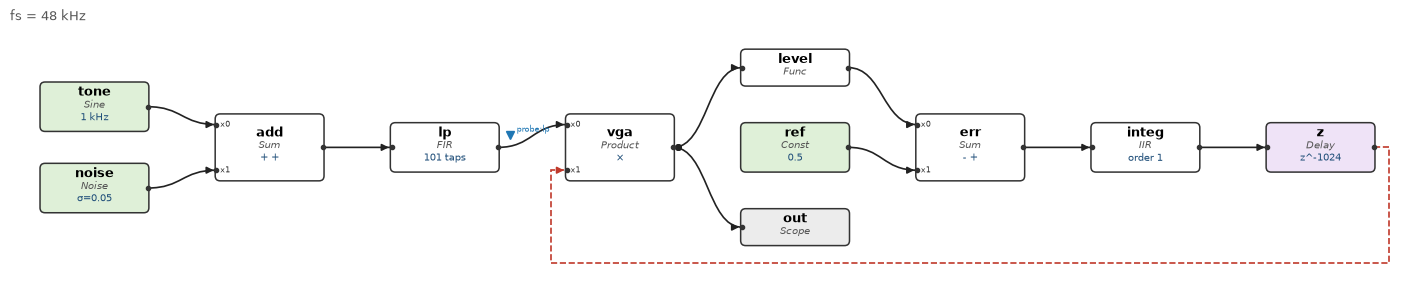

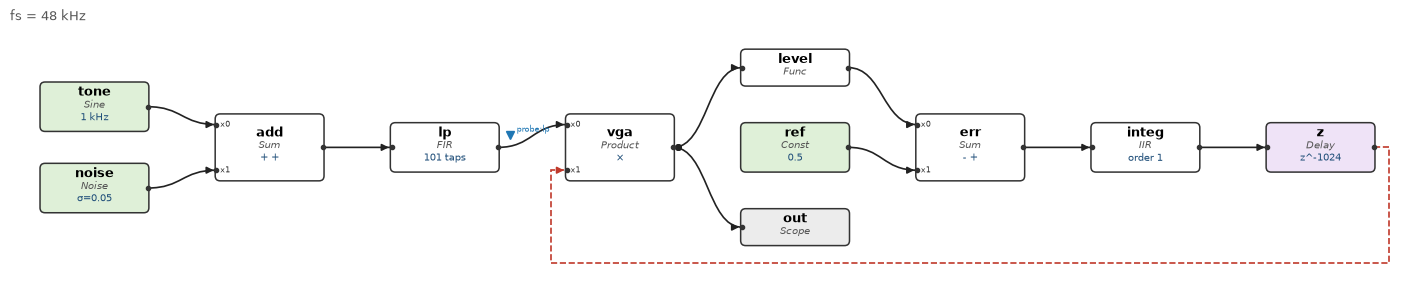

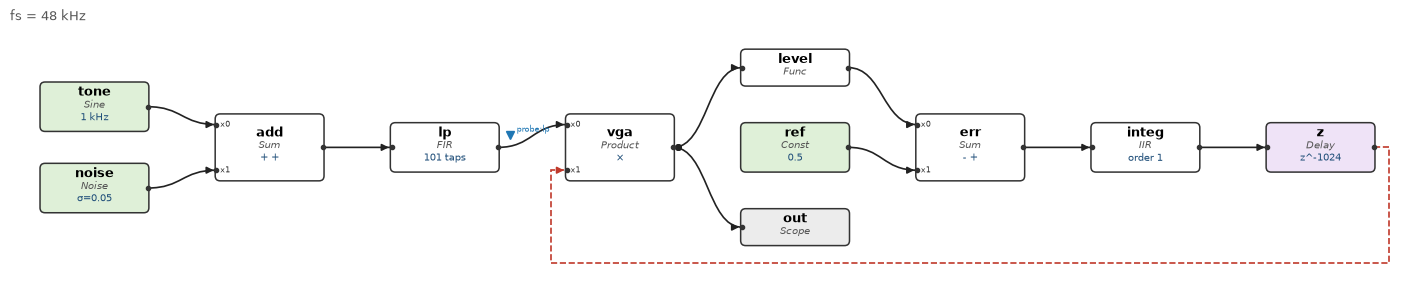

In [5]:
out = Path(tempfile.mkdtemp())
for name in ("agc.pdf", "agc.svg", "agc.png"):
    d.draw(save=out / name)
    print(name, (out / name).stat().st_size, "bytes")

## Graphviz and Mermaid

`d.to_dot()` for `dot -Tpdf` or Typst's `diagraph` package; `d.mermaid()`
for Markdown on GitHub.

In [6]:
print(d.to_dot())

digraph sigline {
  rankdir=LR;
  splines=spline;
  node [shape=record, fontname="Helvetica", fontsize=10,
        style="rounded,filled"];
  edge [arrowsize=0.7];
  b1 [label="{{<i_x0> x0|<i_x1> x1}|add\nSum\n+ +|{<o_y> }}", fillcolor="#ffffff"];
  b2 [label="{{<i_x> }|lp\nFIR\n101 taps|{<o_y> }}", fillcolor="#ffffff"];
  b3 [label="{tone\nSine\n1 kHz|{<o_y> }}", fillcolor="#dff0d8"];
  b4 [label="{noise\nNoise\nσ=0.05|{<o_y> }}", fillcolor="#dff0d8"];
  b5 [label="{{<i_x0> x0|<i_x1> x1}|vga\nProduct\n×|{<o_y> }}", fillcolor="#ffffff"];
  b6 [label="{{<i_x> }|level\nFunc|{<o_y> }}", fillcolor="#ffffff"];
  b7 [label="{{<i_x0> x0|<i_x1> x1}|err\nSum\n- +|{<o_y> }}", fillcolor="#ffffff"];
  b8 [label="{{<i_x> }|integ\nIIR\norder 1|{<o_y> }}", fillcolor="#ffffff"];
  b9 [label="{ref\nConst\n0.5|{<o_y> }}", fillcolor="#dff0d8"];
  b10 [label="{{<i_x> }|z\nDelay\nz^-1024|{<o_y> }}", fillcolor="#efe3f7"];
  b11 [label="{{<i_x> }|out\nScope}", fillcolor="#ececec"];
  b1:o_y:e -> b2:i_x:w;
  

In [7]:
print(d.mermaid())

flowchart LR
  b1["add<br/><small>Sum</small>"]
  b2["lp<br/><small>FIR</small>"]
  b3["tone<br/><small>Sine</small>"]
  b4["noise<br/><small>Noise</small>"]
  b5["vga<br/><small>Product</small>"]
  b6["level<br/><small>Func</small>"]
  b7["err<br/><small>Sum</small>"]
  b8["integ<br/><small>IIR</small>"]
  b9["ref<br/><small>Const</small>"]
  b10["z<br/><small>Delay</small>"]
  b11["out<br/><small>Scope</small>"]
  b1 --> b2
  b2 -->|x0| b5
  b3 -->|x0| b1
  b4 -->|x1| b1
  b5 --> b6
  b5 --> b11
  b6 -->|x0| b7
  b7 --> b8
  b8 --> b10
  b9 -->|x1| b7
  b10 -.->|x1| b5
